In [ ]:
from common import *

In [ ]:
# ERMSD

from mg_sampling.ermsd import eRMSD
from mg_sampling.parallel import ParallelReader

In [ ]:
pdbids = ['7ez0', '9cbu']

In [21]:
results = []

for pdbid in pdbids:
    ref = mda.Universe(
        PROJECT_DIR / f'structures/{pdbid.upper()}_fixed.pdb',
    )

    # Replex
    for sys in ['7ez0', '7ez0_noion']:
        for rep in (0, 1):
            u = mda.Universe(
                PROJECT_DIR / f'replex/{sys}/mMg_tip3p/replicate{rep}/rep{0+8*rep:02d}/input.gro',
                [
                    PROJECT_DIR / f'replex/{sys}/mMg_tip3p/replicate{rep}/rep{i+8*rep:02d}/run.xtc'
                    for i in range(8)
                ],
                format=ParallelReader,
            )
            u.trajectory.demux(
                PROJECT_DIR / f'replex/{sys}/mMg_tip3p/replicate{rep}/rep{0+8*rep:02d}/bias_index.xvg'
            )
            u.trajectory.add_transformations(
                TransformationFromFunction(unwrap_sequential, u.select_atoms("nucleic and not type H"))
            )
            anal = eRMSD(
                u.select_atoms("nucleic and not type H"),
                ref.select_atoms("nucleic and not type H"),
                verbose=True,
            ).run()

            results.append({
                'method': 'replex',
                'forcefield': 'mMg_tip3p',
                'replicate': rep,
                'system': sys,
                'ref': pdbid,
                'times': anal.times,
                'ermsd': anal.results.ermsd,
            })
    
    # Plain MD
    for sys, ff in [
        ('7ez0', 'mMg_tip3p'),
        ('7ez0', 'nMg_tip3p'), 
        ('7ez0', 'nMg_tip3p_soft'),
        ('7ez0_noion', 'nMg_tip3p'),
        ('7ez0_nomg', 'mMg_tip3p'),
    ]:
        for i in range(8):
            u = mda.Universe(
                PROJECT_DIR / f'plain_md/{sys}/{ff}/replicate0/rep{i:02d}/input.gro',
                PROJECT_DIR / f'plain_md/{sys}/{ff}/replicate0/rep{i:02d}/run.xtc',
            )
            u.trajectory.add_transformations(
                TransformationFromFunction(unwrap_sequential, u.select_atoms("nucleic and not type H"))
            )
            anal = eRMSD(
                u.select_atoms("nucleic and not type H"),
                ref.select_atoms("nucleic and not type H"),
                verbose=True,
            ).run(step=8)

            results.append({
                'method': 'plain_md',
                'forcefield': ff,
                'replicate': i,
                'system': sys,
                'ref': pdbid,
                'times': anal.times,
                'ermsd': anal.results.ermsd,
            }) 

/net/sbp/sbpstore2/olanguin/mg_sampling/.venv/lib/python3.11/site-packages/MDAnalysis/coordinates/PDB.py:479: UserWarning: 1 A^3 CRYST1 record, this is usually a placeholder. Unit cell dimensions will be set to None.
  warnings.warn(


  0%|          | 0/2001 [00:00<?, ?it/s]

  0%|          | 0/2001 [00:00<?, ?it/s]

  0%|          | 0/2001 [00:00<?, ?it/s]

  0%|          | 0/2001 [00:00<?, ?it/s]

...

  0%|          | 0/501 [00:00<?, ?it/s]

  0%|          | 0/501 [00:00<?, ?it/s]

  0%|          | 0/501 [00:00<?, ?it/s]

  0%|          | 0/501 [00:00<?, ?it/s]

  0%|          | 0/501 [00:00<?, ?it/s]

In [23]:
df = pd.DataFrame(results)

In [25]:
df.to_parquet('ermsd.parquet')

/net/sbp/sbpstore2/olanguin/mg_sampling/.venv/lib/python3.11/site-packages/IPython/core/events.py:82: UserWarning: constrained_layout not applied because axes sizes collapsed to zero.  Try making figure larger or Axes decorations smaller.
  func(*args, **kwargs)
/net/sbp/sbpstore2/olanguin/mg_sampling/.venv/lib/python3.11/site-packages/IPython/core/pylabtools.py:170: UserWarning: constrained_layout not applied because axes sizes collapsed to zero.  Try making figure larger or Axes decorations smaller.
  fig.canvas.print_figure(bytes_io, **kw)


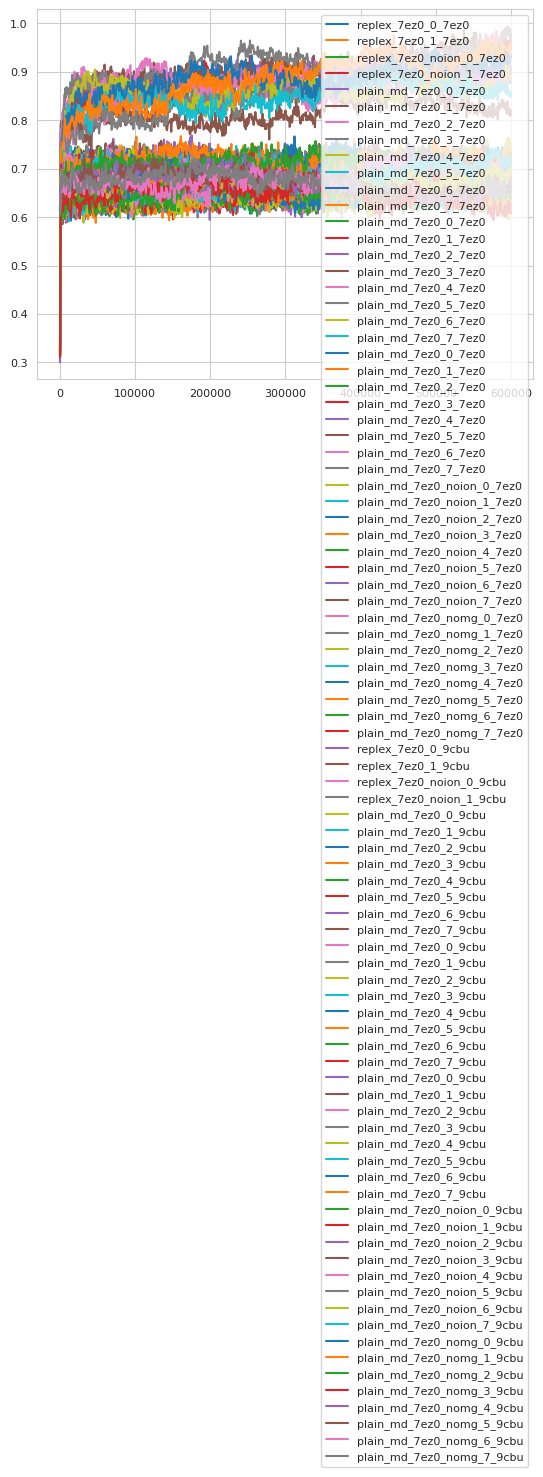

In [22]:
for res in results:
    plt.plot(res['times'], res['ermsd'], label=f"{res['method']}_{res['system']}_{res['replicate']}_{res['ref']}")
plt.legend()
